# Business problem:-  An e-commerce company is experiencing declining profit margin despite consistent revenue growth.
# The management wants to identify the key factors affecting profitability including excessive discounts, rising operational costs, product returns, customer segment and sales performence

In [42]:
#importing all libreries 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [43]:
# importing direct csv file
df = pd.read_csv('ecommerce.csv')
print(f"Data is imported Successfully..!")

Data is imported Successfully..!


In [44]:
print(f"Total Rows:{len(df)}")

Total Rows:50000


In [45]:
df

,order_id,order_date,customer_id,customer_segment,city,region,product_id,product_name,category,sub_category,...,unit_cost,cogs,shipping_cost,marketing_cost,return_cost,net_revenue,profit,profit_margin_pct,return_reason,delivery_days
0,120062,2024-09-24,16425,Corporate,Jaipur,North,2258,Wireless Earbuds,Electronics,Mobiles,...,729.55,729.55,72.65,48.85,0.00,956.36,105.32,11.01,NaN,2.0
1,133676,2024-03-16,13939,Consumer,Chandigarh,North,2510,Wireless Earbuds,Electronics,Audio,...,1174.27,2348.54,131.59,99.73,282.88,87.72,-2775.03,-3163.34,Size/Fit Issue,9.0
2,133023,2024-10-17,19283,Consumer,Jaipur,North,2212,Dumbbell Set,Sports,Equipment,...,3153.82,3153.82,126.20,131.97,0.00,4437.67,1025.68,23.11,NaN,1.0
3,107406,2024-09-21,15417,Corporate,Delhi,North,2026,Denim Jeans,Fashion,Men Clothing,...,913.70,2741.11,280.34,308.13,0.00,3776.14,446.56,11.83,NaN,10.0
4,125550,2024-05-29,13884,Consumer,Surat,West,2021,Denim Jeans,Fashion,Men Clothing,...,223.68,447.36,98.68,28.43,0.00,684.72,110.24,16.10,NaN,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,142298,2024-10-30,7287,Consumer,Bhopal,Central,2305,Smart Watch,Electronics,Laptops,...,396.62,793.25,192.40,88.18,0.00,1186.37,112.55,9.49,NaN,5.0
49996,133175,2023-03-11,22727,Consumer,Raipur,Central,2583,Face Serum,Beauty,Fragrance,...,529.78,529.78,86.10,31.77,0.00,799.58,151.93,19.00,NaN,3.0
49997,146471,2023-12-10,10272,Small Business,Bhopal,Central,2046,Wireless Earbuds,Electronics,Laptops,...,449.18,449.18,63.33,20.26,0.00,559.12,26.35,4.71,NaN,1.0
49998,134960,2024-10-26,16362,Consumer,Pune,West,2133,Smart Watch,Electronics,Accessories,...,1733.10,6932.41,452.09,856.65,0.00,10513.33,2272.19,21.61,NaN,NaN


#Data Cleaning

In [46]:
print(f"Total duplicates rows: {df.duplicated().sum()}")

Total duplicates rows: 1000


In [47]:
df.drop_duplicates(inplace = True)

In [48]:
print(f"Remine duplicates: {df.duplicated().sum()}")

Remine duplicates: 0


In [49]:
print(f"Total Remain Rows:{len(df)}")

Total Remain Rows:49000


In [50]:
# checking null values
df.isnull().sum()

order_id                 0
order_date               5
customer_id              0
customer_segment       294
city                   196
region                   0
product_id               0
product_name             0
category                 0
sub_category             0
brand                  392
quantity                 0
unit_list_price          0
discount_pct           147
sales_channel            0
payment_method         196
order_status             0
sales_amount             0
discount_amount          0
refund_amount            0
unit_cost                0
cogs                     0
shipping_cost          147
marketing_cost         147
return_cost              0
net_revenue              0
profit                   0
profit_margin_pct        0
return_reason        41948
delivery_days          196
dtype: int64

In [51]:
df['customer_segment'] = df['customer_segment'].fillna('Unknown')
df['city'] = df['city'].fillna('Unknown')
df['brand'] = df['brand'].fillna('Unknown')
df['payment_method'] = df['payment_method'].fillna('Unknown')
df['return_reason'] = df['return_reason'].fillna('Not Returned')

In [52]:
df = df.dropna(subset=['order_date'])
df['discount_pct'] = (df['discount_amount']/(df['quantity']*df['unit_list_price'])*100)
for col in ['shipping_cost','marketing_cost']:
    df[col] = df[col].fillna(df.groupby('category')[col].transform('median'))
df['delivery_days'] = df['delivery_days'].fillna(df.groupby('region')['delivery_days'].transform('median'))

In [53]:
df['discount_pct'] = df['discount_pct'].fillna(0)

In [54]:
# checking null values
df.isnull().sum()

order_id             0
order_date           0
customer_id          0
customer_segment     0
city                 0
region               0
product_id           0
product_name         0
category             0
sub_category         0
brand                0
quantity             0
unit_list_price      0
discount_pct         0
sales_channel        0
payment_method       0
order_status         0
sales_amount         0
discount_amount      0
refund_amount        0
unit_cost            0
cogs                 0
shipping_cost        0
marketing_cost       0
return_cost          0
net_revenue          0
profit               0
profit_margin_pct    0
return_reason        0
delivery_days        0
dtype: int64

In [80]:
df.dtypes

order_id                      int64
order_date           datetime64[us]
customer_id                   int64
customer_segment                str
city                            str
region                          str
product_id                    int64
product_name                    str
category                        str
sub_category                    str
brand                           str
quantity                      int64
unit_list_price             float64
discount_pct                float64
sales_channel                   str
payment_method                  str
order_status                    str
sales_amount                float64
discount_amount             float64
refund_amount               float64
unit_cost                   float64
cogs                        float64
shipping_cost               float64
marketing_cost              float64
return_cost                 float64
net_revenue                 float64
profit                      float64
profit_margin_pct           

In [56]:
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed',dayfirst=True,errors='coerce')

In [79]:
df['year'] = df['year'].astype(str)

In [57]:
df['customer_segment'].unique()

<StringArray>
['Corporate', 'Consumer', 'Small Business', 'Unknown']
Length: 4, dtype: str

In [58]:
# Categories check
for c in ['order_status','sales_channel','payment_method','region','customer_segment','city','sub_category','return_reason','category','brand']:
    print(df[c].value_counts(),'\n')

order_status
Delivered      41461
Returned        3573
Cancelled       1610
In Transit      1470
RETURNED         236
cancelled        226
 delivered       220
IN TRANSIT       199
Name: count, dtype: int64 

sales_channel
Mobile App      18320
Website         14447
Marketplace     11574
Retail Store     3773
 MOBILE APP       239
website           232
RETAIL STORE      214
marketplace       196
Name: count, dtype: int64 

payment_method
Credit Card          9714
Cash on Delivery     9642
Debit Card           9584
UPI                  9542
Net Banking          9436
Unknown               196
cash on delivery      194
upi                   176
Credit card           176
net banking           170
 DEBIT CARD           165
Name: count, dtype: int64 

region
West        11749
North       10502
South        9592
Central      8592
East         7679
 north        181
east          179
 WEST         176
SOUTH         174
Central       171
Name: count, dtype: int64 

customer_segment
Consumer    

In [59]:
df['order_status'].unique()

<StringArray>
[  'Delivered',    'Returned',   'Cancelled',  'IN TRANSIT',  'In Transit',
 ' delivered ',  'cancelled ',    'RETURNED']
Length: 8, dtype: str

In [60]:
df['order_status'] = df['order_status'].str.strip().str.title()

In [61]:
df['order_status'].unique()

<StringArray>
['Delivered', 'Returned', 'Cancelled', 'In Transit']
Length: 4, dtype: str

In [62]:
df['order_status'] =  df['order_status'].str.replace(' ','_')

In [63]:
df['sales_channel'] = df['sales_channel'].str.strip().str.title()

In [64]:
df['sales_channel'].unique()

<StringArray>
['Mobile App', 'Website', 'Marketplace', 'Retail Store']
Length: 4, dtype: str

In [65]:
df['sales_channel'] = df['sales_channel'].str.replace(' ','_')

In [66]:
df['payment_method'] = df['payment_method'].str.strip().str.title()

In [67]:
df['payment_method'].unique()

<StringArray>
['Cash On Delivery',      'Credit Card',       'Debit Card',
              'Upi',      'Net Banking',          'Unknown']
Length: 6, dtype: str

In [68]:
df['payment_method'] = df['payment_method'].str.replace(' ','_')

In [69]:
df['region'] = df['region'].str.strip().str.title()

In [70]:
df['region'].unique()

<StringArray>
['North', 'West', 'South', 'Central', 'East']
Length: 5, dtype: str

In [71]:
df['category'] = df['category'].str.strip().str.title()

In [72]:
df['category'].unique()

<StringArray>
['Electronics', 'Sports', 'Fashion', 'Home & Kitchen', 'Beauty']
Length: 5, dtype: str

In [73]:
# Categories check
for c in ['order_status','sales_channel','payment_method','region','customer_segment','city','sub_category','return_reason','category','brand']:
    print(df[c].value_counts(),'\n')

order_status
Delivered     41681
Returned       3809
Cancelled      1836
In_Transit     1669
Name: count, dtype: int64 

sales_channel
Mobile_App      18559
Website         14679
Marketplace     11770
Retail_Store     3987
Name: count, dtype: int64 

payment_method
Credit_Card         9890
Cash_On_Delivery    9836
Debit_Card          9749
Upi                 9718
Net_Banking         9606
Unknown              196
Name: count, dtype: int64 

region
West       11925
North      10683
South       9766
Central     8763
East        7858
Name: count, dtype: int64 

customer_segment
Consumer          32898
Corporate          9938
Small Business     5865
Unknown             294
Name: count, dtype: int64 

city
Surat          3047
Ahmedabad      3017
Pune           2950
Mumbai         2897
Lucknow        2730
Jaipur         2649
Chandigarh     2638
Delhi          2635
Chennai        2479
Hyderabad      2458
Bengaluru      2453
Kochi          2336
Nagpur         2196
Indore         2174
Raipur    

# Columns are cleaned successfully...!

In [74]:
df = df[df.order_status!='Cancelled'].copy()
df['year'] = df.order_date.dt.year
df['quarter'] = df.order_date.dt.to_period('Q')

In [75]:
df.head()

,order_id,order_date,customer_id,customer_segment,city,region,product_id,product_name,category,sub_category,...,shipping_cost,marketing_cost,return_cost,net_revenue,profit,profit_margin_pct,return_reason,delivery_days,year,quarter
0,120062,2024-09-24,16425,Corporate,Jaipur,North,2258,Wireless Earbuds,Electronics,Mobiles,...,72.65,48.85,0.00,956.36,105.32,11.01,Not Returned,2.0,2024.0,2024Q3
1,133676,2024-03-16,13939,Consumer,Chandigarh,North,2510,Wireless Earbuds,Electronics,Audio,...,131.59,99.73,282.88,87.72,-2775.03,-3163.34,Size/Fit Issue,9.0,2024.0,2024Q1
2,133023,2024-10-17,19283,Consumer,Jaipur,North,2212,Dumbbell Set,Sports,Equipment,...,126.20,131.97,0.00,4437.67,1025.68,23.11,Not Returned,1.0,2024.0,2024Q4
3,107406,2024-09-21,15417,Corporate,Delhi,North,2026,Denim Jeans,Fashion,Men Clothing,...,280.34,308.13,0.00,3776.14,446.56,11.83,Not Returned,10.0,2024.0,2024Q3
4,125550,2024-05-29,13884,Consumer,Surat,West,2021,Denim Jeans,Fashion,Men Clothing,...,98.68,28.43,0.00,684.72,110.24,16.10,Not Returned,8.0,2024.0,2024Q2


#Now EDA Performed started  

In [76]:
# Total KPIs
print(f"Total orders: {len(df)}")
print(f"\nTotal Revenue: {round(df.net_revenue.sum(),2)}")
print(f"\nTotal Profit: {round(df.profit.sum(),2)}")
print(f"\nProfit margin%: {round(df.profit.sum()/df.net_revenue.sum()*100,2)}")
print(f"\nAOV: {round(df.net_revenue.sum()/df.order_id.nunique(),2)}")
print(f"\nReturn Rate %: {round((df.order_status =='Returned').mean()*100,2)}")
print(f"\nTop performing Product: {round(df.groupby('product_name')['net_revenue'].sum().nlargest(1),2)}")
print(f"\nTop performing category: {round(df.groupby('category')['net_revenue'].sum().nlargest(1),2)}")

Total orders: 47159

Total Revenue: 114849217.39

Total Profit: 7164066.27

Profit margin%: 6.24

AOV: 2435.36

Return Rate %: 8.08

Top performing Product: product_name
Wireless Earbuds    10166513.13
Name: net_revenue, dtype: float64

Top performing category: category
Electronics    48547404.91
Name: net_revenue, dtype: float64


#EDA Started from here 

In [77]:
# Now the basis of the year
df.groupby('year')[['net_revenue', 'profit']].sum()

,net_revenue,profit
year,,
2023.0,39040206.85,3653064.28
2024.0,38465563.17,2533278.86
2025.0,37313846.10,982242.26


# insight:- Net revenue 2023 to 2025 only 4.4% decresed (39.04M->37.31M) that means sales almost stable
# but profit Margin ~73% decresed (3.65M->0.98M) 9.4% to 2.6% 
# that means revenue decreased 3% but profit 61%  

In [81]:
df.groupby('year')[['cogs','discount_amount','shipping_cost','marketing_cost','return_cost','refund_amount']].sum()

,cogs,discount_amount,shipping_cost,marketing_cost,return_cost,refund_amount
year,,,,,,
2023.0,30328289.51,4970601.39,2200367.400,2298746.19,554315.53,4767966.37
2024.0,30579137.67,6099703.03,2328189.295,2456357.30,560080.69,4728265.59
2025.0,30692485.86,7396221.02,2501340.570,2560498.51,568954.73,4789376.35


# Discount spend 2023 to 2025 ~49% increased(4.97M->7.40M) while revenue decreased ~4.4% that is the biggest reason of decreaseing profit margin..

# Recommendation:- Review the discount strategy which category and channel or customer segement has been increased discount and set the limit

In [83]:
df.groupby(['year','category'])['discount_amount'].sum().unstack()

category,Beauty,Electronics,Fashion,Home & Kitchen,Sports
year,,,,,
2023.0,470279.78,2022860.14,811013.45,1122555.26,543892.76
2024.0,548090.71,2605382.30,985782.52,1303588.69,656858.81
2025.0,670425.81,3195441.91,1190084.76,1581181.31,759087.23


# Electronic has the highest discount amount as compare to other category (+1.17M) +58% and also electronic have genrated top revenue

# Recommendations:- Apply discount cap in electronice and check volume has increases or not, if not then this discount decreased only margin

In [88]:
d = df.groupby(['year','category'])[['discount_amount','sales_amount']].sum()
d['discount_rate_pct'] = d['discount_amount']/d['sales_amount']*100
d['discount_rate_pct'].unstack().round(2)

category,Beauty,Electronics,Fashion,Home & Kitchen,Sports
year,,,,,
2023.0,10.27,10.25,10.08,10.19,10.12
2024.0,12.17,12.41,12.53,12.33,12.32
2025.0,14.97,15.11,14.80,14.74,14.93


# insights:- 2023 to 2025 disount rate is continously increasing in all category So

# Recommendation:- So apply company-wide discount cap around(10-12%)

In [89]:
df.groupby('year')['quantity'].sum()

year
2023.0    28321
2024.0    28281
2025.0    28273
Name: quantity, dtype: int64

# insights :- after increasing discount volume does't affected  

# recommendation:- Apply company-wide discount cap (10-20%), in data there is no gaining in volume after discount so after the applying cap the risk of decreasing sales would be low

In [91]:
yearly_margin = (df.groupby('year').apply(lambda x: x['profit'].sum() / x['net_revenue'].sum() * 100).round(2))
print(yearly_margin)

year
2023.0    9.36
2024.0    6.59
2025.0    2.63
dtype: float64


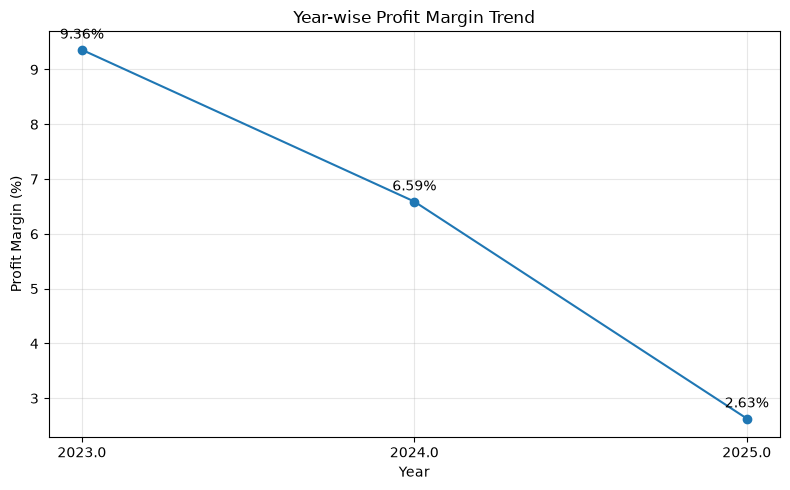

In [92]:
plt.figure(figsize=(8, 5))
plt.plot(yearly_margin.index, yearly_margin.values, marker='o')
for x, y in zip(yearly_margin.index, yearly_margin.values):
    plt.annotate(f'{y:.2f}%', (x, y), xytext=(0, 8),textcoords='offset points', ha='center')
plt.title('Year-wise Profit Margin Trend')
plt.xlabel('Year')
plt.ylabel('Profit Margin (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# insight:- As you can see profit margin is decreasing year by year 

In [96]:
df = df.dropna(subset=['year']).copy()

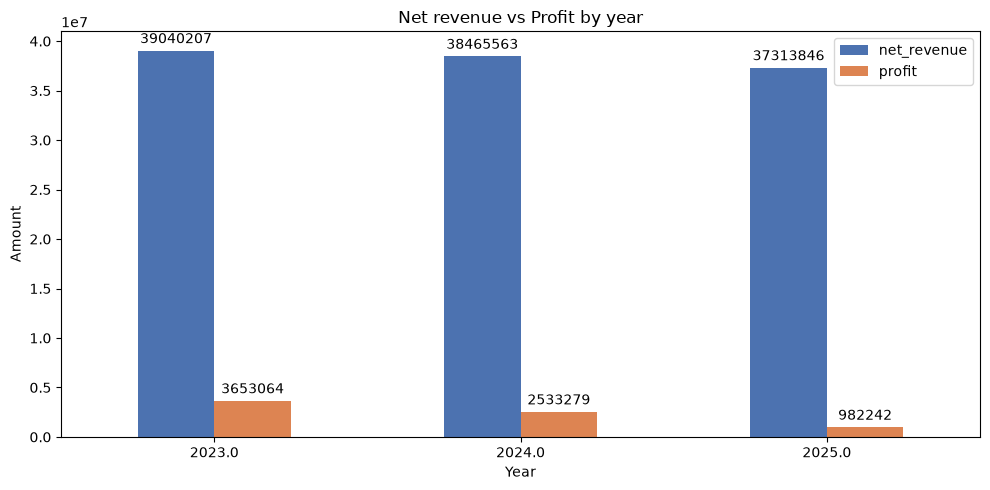

In [109]:
yearly = df.groupby('year')[['net_revenue', 'profit']].sum()
ax = yearly.plot(kind='bar',figsize=(10,5), title='Net revenue vs Profit by year',color=['#4C72B0','#DD8452'])
for c in ax.containers:
    ax.bar_label(c,fmt='%.0f',padding = 3)
plt.xlabel('Year', fontsize=10)
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

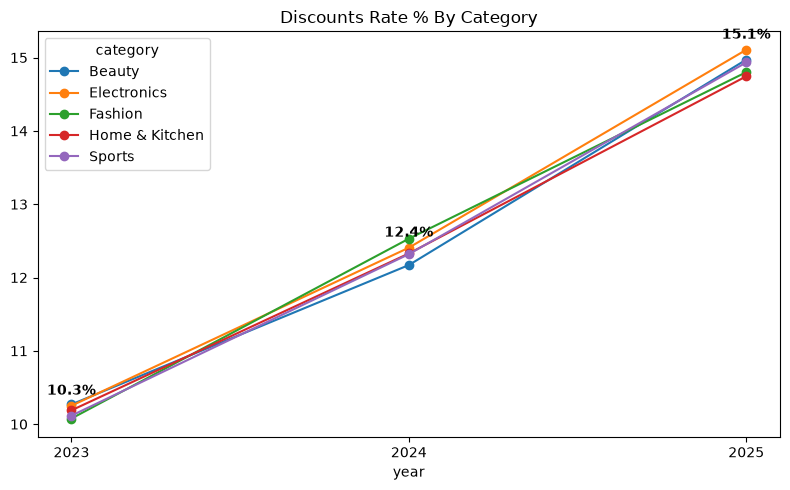

In [122]:
d = df.groupby(['year','category'])[['discount_amount','sales_amount']].sum()
rate = (d['discount_amount']/d['sales_amount']*100).unstack()
ax = rate.plot(marker = 'o',figsize=(8,5))
for x,y in zip(rate.index, rate['Electronics']):
    ax.annotate(f'{y:.1f}%',(x,y),textcoords='offset points',
               xytext=(0,8), ha='center',fontweight='bold')
ax.set_xticks(rate.index)
ax.set_title('Discounts Rate % By Category')
plt.tight_layout()
plt.show()

# Insights:- AS you can see discount pct is increasing from 2023 to 2025 in every category..

In [113]:
print(rate.index)
print(df['year'].dtype)

Index(['2023.0', '2024.0', '2025.0'], dtype='str', name='year')
str


In [120]:
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df = df.dropna(subset=['year']).copy()
df['year'] = df['year'].astype(int)

In [121]:
print(rate.index)
print(df['year'].dtype)

Index(['2023.0', '2024.0', '2025.0'], dtype='str', name='year')
int64


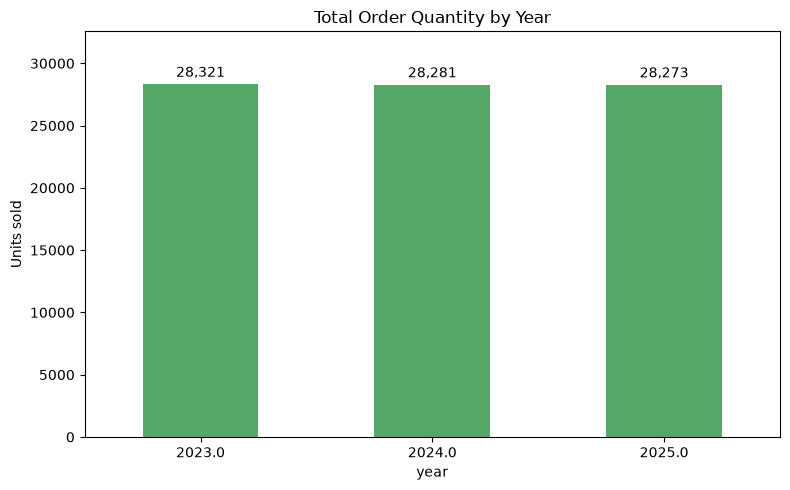

In [112]:
qty = df.groupby('year')['quantity'].sum()
ax = qty.plot(kind='bar',figsize=(8,5),color='#55A868')
ax.bar_label(ax.containers[0], labels=[f'{v:,}'for v in qty],padding=3)
ax.set_ylim(0,qty.max()*1.15)
ax.set_title('Total Order Quantity by Year')
ax.set_ylabel('Units sold')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Insights :- Net revenue declined only ~4% from 2023 to 2025, but profit fell 73% and margin dropped from 9.4% to 2.6%.
# **The main driver was discounting**: the discount rate rose from 10% to 15% across all five categories, while order quantity 
# stayed flat. This points to a company-wide discount policy change that eroded margin without increasing demand 

# Recommendation:-
# 1. **Apply a company-wide discount cap of 10-12%** The discount rate rose from 10.3% to 15.1% between 2023 and 2025, while order quantity stayed flat at about 28.3k units the extra discount did not generate extra sales.
# 2. **Track the volume impact of over every promotion.** Measure order volume before and after each campaign, and stop discounts that do not lift orders.
# 3. **Shift from blanket discounts to targeted ones ** Offer discounts only on show-moving products or clearance items, where they can actually increase volume
# 4. **Review shipping and marketing costs** Shipping(+14%) and marketing (+11%) grew faster then revenue (-4%), contributibg to the decline in profit

In [124]:
df.to_csv('ecommerce_cleaned.csv',index=False)